In [3]:
import pandas as pd, numpy as np, glob, os
import matplotlib.pyplot as plt

RAW = r"C:\Users\DELL\Desktop\Projet_DDoS\data\raw"
PROCESSED = r"C:\Users\DELL\Desktop\Projet_DDoS\data\processed"

print("Dossier existe :", os.path.exists(RAW))

files = glob.glob(RAW + r"\**\*.csv", recursive=True)
print(len(files), "fichiers CSV trouvés")
for f in files:
    print(os.path.basename(f), round(os.path.getsize(f)/1e9, 2), "Go")

Dossier existe : True
16 fichiers CSV trouvés
DrDoS_DNS.csv 2.13 Go
DrDoS_LDAP.csv 0.92 Go
DrDoS_MSSQL.csv 1.89 Go
DrDoS_NetBIOS.csv 1.7 Go
DrDoS_NTP.csv 0.65 Go
DrDoS_SNMP.csv 2.17 Go
DrDoS_SSDP.csv 1.25 Go
DrDoS_UDP.csv 1.51 Go
LDAP.csv 0.87 Go
MSSQL.csv 2.39 Go
NetBIOS.csv 1.42 Go
Portmap.csv 0.08 Go
Syn.csv 0.64 Go
TFTP.csv 9.3 Go
UDP.csv 1.79 Go
UDPLag.csv 0.16 Go


In [9]:
pip install pandas numpy pyarrow matplotlib seaborn scikit-learn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached tzdata-2026.5-py2.py3-none-any.whl.metadata (1.4 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached narwhals-2.27.1-py3-none-any.whl.metadata (15 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
   ---------------------------------------- 0.0/9.8 MB ? eta -:--:--
   --- ------------------------------------ 0.8/9.8 MB 3.2 MB/s eta 0:00:03
   ----- ---------------------------------- 1.3/9.8 MB 2.9 MB/s eta 0:00:03
   ---------- ----------------------------- 2.6/9.8 MB 4.2 MB/s eta 0:00:02
   --------------------- ------------------ 5.2/9.8 MB 6.2 MB/s eta 0:00:01
   ----------------------- ---------------- 5.8/9.8 MB 6.2 MB/s eta 0:00:01
   --------------------

In [4]:
sample = pd.read_csv(files[0], nrows=5)
print(sample.shape)
print(sample.columns.tolist())
sample.head()

(5, 88)
['Unnamed: 0', 'Flow ID', ' Source IP', ' Source Port', ' Destination IP', ' Destination Port', ' Protocol', ' Timestamp', ' Flow Duration', ' Total Fwd Packets', ' Total Backward Packets', 'Total Length of Fwd Packets', ' Total Length of Bwd Packets', ' Fwd Packet Length Max', ' Fwd Packet Length Min', ' Fwd Packet Length Mean', ' Fwd Packet Length Std', 'Bwd Packet Length Max', ' Bwd Packet Length Min', ' Bwd Packet Length Mean', ' Bwd Packet Length Std', 'Flow Bytes/s', ' Flow Packets/s', ' Flow IAT Mean', ' Flow IAT Std', ' Flow IAT Max', ' Flow IAT Min', 'Fwd IAT Total', ' Fwd IAT Mean', ' Fwd IAT Std', ' Fwd IAT Max', ' Fwd IAT Min', 'Bwd IAT Total', ' Bwd IAT Mean', ' Bwd IAT Std', ' Bwd IAT Max', ' Bwd IAT Min', 'Fwd PSH Flags', ' Bwd PSH Flags', ' Fwd URG Flags', ' Bwd URG Flags', ' Fwd Header Length', ' Bwd Header Length', 'Fwd Packets/s', ' Bwd Packets/s', ' Min Packet Length', ' Max Packet Length', ' Packet Length Mean', ' Packet Length Std', ' Packet Length Varianc

,Unnamed: 0,Flow ID,Source IP,Source Port,Destination IP,Destination Port,Protocol,Timestamp,Flow Duration,Total Fwd Packets,...,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,SimillarHTTP,Inbound,Label
0,425,172.16.0.5-192.168.50.1-634-60495-17,172.16.0.5,634,192.168.50.1,60495,17,2018-12-01 10:51:39.813448,28415,97,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1,DrDoS_DNS
1,430,172.16.0.5-192.168.50.1-60495-634-17,192.168.50.1,634,172.16.0.5,60495,17,2018-12-01 10:51:39.820842,2,2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,DrDoS_DNS
2,1654,172.16.0.5-192.168.50.1-634-46391-17,172.16.0.5,634,192.168.50.1,46391,17,2018-12-01 10:51:39.852499,48549,200,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1,DrDoS_DNS
3,2927,172.16.0.5-192.168.50.1-634-11894-17,172.16.0.5,634,192.168.50.1,11894,17,2018-12-01 10:51:39.890213,48337,200,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1,DrDoS_DNS
4,694,172.16.0.5-192.168.50.1-634-27878-17,172.16.0.5,634,192.168.50.1,27878,17,2018-12-01 10:51:39.941151,32026,200,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1,DrDoS_DNS


In [3]:
import os

RAW = r"C:\Users\DELL\Desktop\Projet_DDoS\data\raw"
print("Dossier existe :", os.path.exists(RAW))

# Contenu réel du dossier (tous types de fichiers)
for root, dirs, fs in os.walk(RAW):
    for f in fs[:15]:
        p = os.path.join(root, f)
        print(p, "->", round(os.path.getsize(p)/1e9, 2), "Go")

# Recalcul de la liste des CSV
files = [os.path.join(r, f) for r, d, fs in os.walk(RAW)
         for f in fs if f.lower().endswith(".csv")]
print(len(files), "fichiers CSV trouvés")

Dossier existe : True
C:\Users\DELL\Desktop\Projet_DDoS\data\raw\.~lock.UDPLag.csv# -> 0.0 Go
C:\Users\DELL\Desktop\Projet_DDoS\data\raw\DrDoS_DNS.csv -> 2.13 Go
C:\Users\DELL\Desktop\Projet_DDoS\data\raw\DrDoS_LDAP.csv -> 0.92 Go
C:\Users\DELL\Desktop\Projet_DDoS\data\raw\DrDoS_MSSQL.csv -> 1.89 Go
C:\Users\DELL\Desktop\Projet_DDoS\data\raw\DrDoS_NetBIOS.csv -> 1.7 Go
C:\Users\DELL\Desktop\Projet_DDoS\data\raw\DrDoS_NTP.csv -> 0.65 Go
C:\Users\DELL\Desktop\Projet_DDoS\data\raw\DrDoS_SNMP.csv -> 2.17 Go
C:\Users\DELL\Desktop\Projet_DDoS\data\raw\DrDoS_SSDP.csv -> 1.25 Go
C:\Users\DELL\Desktop\Projet_DDoS\data\raw\DrDoS_UDP.csv -> 1.51 Go
C:\Users\DELL\Desktop\Projet_DDoS\data\raw\LDAP.csv -> 0.87 Go
C:\Users\DELL\Desktop\Projet_DDoS\data\raw\MSSQL.csv -> 2.39 Go
C:\Users\DELL\Desktop\Projet_DDoS\data\raw\NetBIOS.csv -> 1.42 Go
C:\Users\DELL\Desktop\Projet_DDoS\data\raw\Portmap.csv -> 0.08 Go
C:\Users\DELL\Desktop\Projet_DDoS\data\raw\Syn.csv -> 0.64 Go
C:\Users\DELL\Desktop\Projet_DDoS

In [5]:
def load_sample(path, frac=0.02, chunksize=500_000):
    parts = []
    for chunk in pd.read_csv(path, chunksize=chunksize, low_memory=False):
        chunk.columns = chunk.columns.str.strip()
        num = chunk.select_dtypes("float64").columns
        chunk[num] = chunk[num].astype("float32")
        benign = chunk[chunk["Label"] == "BENIGN"]
        attack = chunk[chunk["Label"] != "BENIGN"].sample(frac=frac, random_state=42)
        part = pd.concat([benign, attack])
        part["source_file"] = os.path.basename(path)
        part["day"] = os.path.basename(os.path.dirname(path))
        parts.append(part)
    return pd.concat(parts, ignore_index=True)

dfs = []
for f in files:
    print("Chargement :", os.path.basename(f))
    dfs.append(load_sample(f))

df = pd.concat(dfs, ignore_index=True)
del dfs

print(df.shape)
print(df["Label"].value_counts())
print(df.groupby(["day", "Label"]).size())

Chargement : DrDoS_DNS.csv
Chargement : DrDoS_LDAP.csv
Chargement : DrDoS_MSSQL.csv
Chargement : DrDoS_NetBIOS.csv
Chargement : DrDoS_NTP.csv
Chargement : DrDoS_SNMP.csv
Chargement : DrDoS_SSDP.csv
Chargement : DrDoS_UDP.csv
Chargement : LDAP.csv
Chargement : MSSQL.csv
Chargement : NetBIOS.csv
Chargement : Portmap.csv
Chargement : Syn.csv
Chargement : TFTP.csv
Chargement : UDP.csv
Chargement : UDPLag.csv
(1380123, 90)
Label
TFTP             401649
MSSQL            115734
DrDoS_SNMP       103197
DrDoS_DNS        101420
DrDoS_MSSQL       90449
DrDoS_NetBIOS     81865
UDP               75106
BENIGN            73970
NetBIOS           73147
DrDoS_UDP         62693
DrDoS_SSDP        52212
DrDoS_LDAP        43598
LDAP              38307
Syn               31646
DrDoS_NTP         24053
UDP-lag            7328
Portmap            3739
WebDDoS              10
Name: count, dtype: int64
day  Label        
raw  BENIGN            73970
     DrDoS_DNS        101420
     DrDoS_LDAP        43598
     DrD

In [6]:
print("Shape avant nettoyage :", df.shape)

# 1. Colonnes d'identification (risque de fuite de données)
drop_cols = [c for c in ["Unnamed: 0", "Flow ID", "Source IP", "Destination IP","Source Port", "Destination Port", "Timestamp", "SimillarHTTP"]
              if c in df.columns]
df = df.drop(columns=drop_cols)

# 2. Infinis -> NaN, puis suppression des NaN
df = df.replace([np.inf, -np.inf], np.nan)
print("NaN :", df.isna().sum().sum())
df = df.dropna()

# 3. Doublons (on compare sans source_file ni day)
feat_cols = [c for c in df.columns if c not in ["source_file", "day"]]
print("Doublons :", df.duplicated(subset=feat_cols).sum())
df = df.drop_duplicates(subset=feat_cols)

# 4. Colonnes constantes
const = [c for c in feat_cols if df[c].nunique() <= 1]
print("Colonnes constantes :", const)
df = df.drop(columns=const)

# 5. On met source_file et day à part (pour l'étape des attaques inconnues)
meta = df[["source_file", "day", "Label"]].copy()
df = df.drop(columns=["source_file", "day"])

print("Shape après nettoyage :", df.shape)

Shape avant nettoyage : (1380123, 90)
NaN : 74952
Doublons : 923403
Colonnes constantes : ['Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'FIN Flag Count', 'PSH Flag Count', 'ECE Flag Count', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']
Shape après nettoyage : (419244, 68)


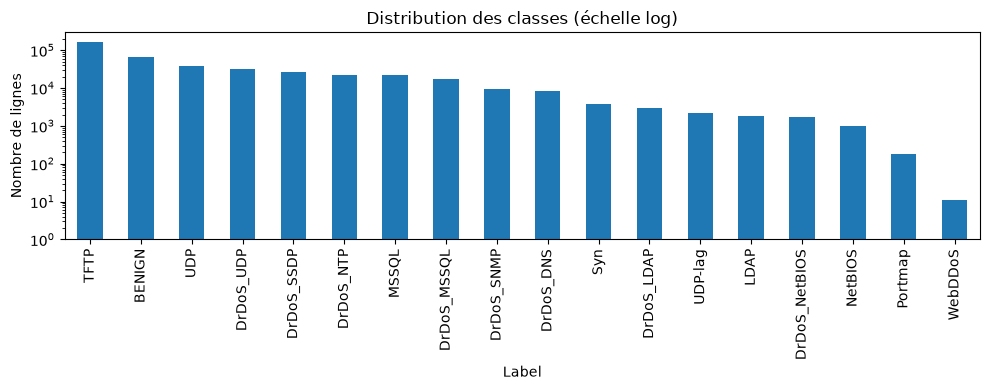

Label
False    0.843709
True     0.156291
Name: proportion, dtype: float64


,count,mean,std,min,25%,50%,75%,max
Protocol,419244.0,1.576735e+01,3.507947e+00,0.000000,17.000000,17.000000,1.700000e+01,1.700000e+01
Flow Duration,419244.0,3.873954e+06,1.442131e+07,1.000000,4269.000000,213903.000000,3.000941e+06,1.200000e+08
Total Fwd Packets,419244.0,1.068191e+01,4.531333e+02,1.000000,2.000000,4.000000,6.000000e+00,9.989700e+04
Total Backward Packets,419244.0,1.299420e+00,5.242507e+01,0.000000,0.000000,0.000000,0.000000e+00,3.170000e+04
Total Length of Fwd Packets,419244.0,3.506831e+03,3.016371e+04,0.000000,1274.000000,2064.000000,2.088000e+03,1.526642e+07
Total Length of Bwd Packets,419244.0,1.045162e+03,1.016310e+05,0.000000,0.000000,0.000000,0.000000e+00,5.842950e+07
Fwd Packet Length Max,419244.0,4.629996e+02,3.126069e+02,0.000000,389.000000,516.000000,5.160000e+02,3.212000e+04
Fwd Packet Length Min,419244.0,4.231813e+02,2.933844e+02,0.000000,321.000000,472.000000,5.160000e+02,2.033000e+03
Fwd Packet Length Mean,419244.0,4.375867e+02,2.856590e+02,0.000000,348.000000,477.000000,5.160000e+02,3.015291e+03
Fwd Packet Length Std,419244.0,1.539340e+01,5.809844e+01,0.000000,0.000000,0.000000,2.251666e+01,2.221556e+03


In [7]:
# Distribution des classes
df["Label"].value_counts().plot(kind="bar", figsize=(10, 4), log=True)
plt.title("Distribution des classes (échelle log)")
plt.ylabel("Nombre de lignes")
plt.tight_layout()
plt.show()

# Proportion bénin / attaque
print((df["Label"] == "BENIGN").value_counts(normalize=True))

# Résumé statistique
df.describe().T.head(20)

In [8]:
df.to_parquet(PROCESSED + r"\sample_clean.parquet", index=False)
meta.to_parquet(PROCESSED + r"\sample_meta.parquet", index=False)

print("Sauvegardé :", df.shape)
print(os.listdir(PROCESSED))

Sauvegardé : (419244, 68)
['sample_clean.parquet', 'sample_meta.parquet']


Label
TFTP             163151
BENIGN            65524
UDP               37809
DrDoS_UDP         31547
DrDoS_SSDP        26324
DrDoS_NTP         22833
MSSQL             22809
DrDoS_MSSQL       17670
DrDoS_SNMP         9236
DrDoS_DNS          8543
Syn                3902
DrDoS_LDAP         2936
UDP-lag            2208
LDAP               1875
DrDoS_NetBIOS      1706
NetBIOS             981
Portmap             180
WebDDoS              10
Name: count, dtype: int64
Label
TFTP             38.92
BENIGN           15.63
UDP               9.02
DrDoS_UDP         7.52
DrDoS_SSDP        6.28
DrDoS_NTP         5.45
MSSQL             5.44
DrDoS_MSSQL       4.21
DrDoS_SNMP        2.20
DrDoS_DNS         2.04
Syn               0.93
DrDoS_LDAP        0.70
UDP-lag           0.53
LDAP              0.45
DrDoS_NetBIOS     0.41
NetBIOS           0.23
Portmap           0.04
WebDDoS           0.00
Name: count, dtype: float64


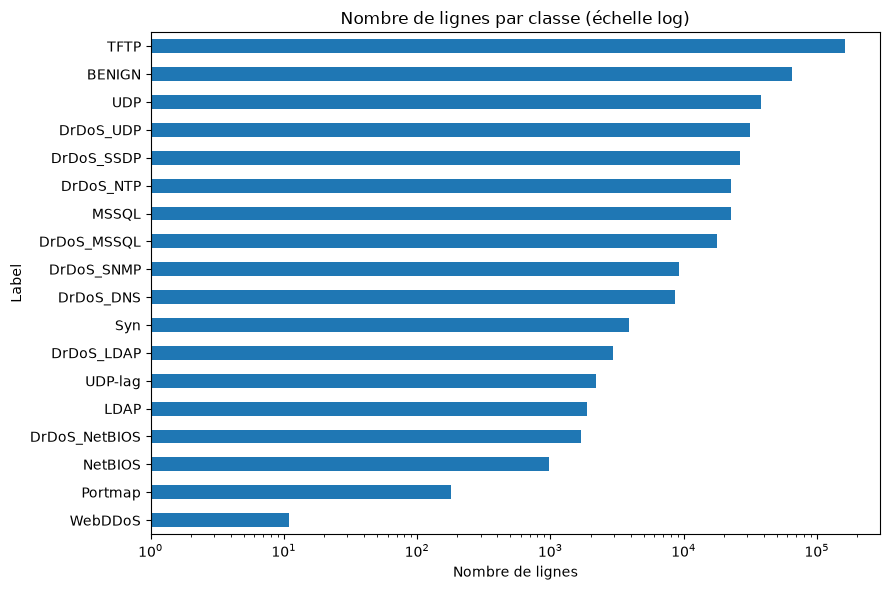

In [9]:
counts = df["Label"].value_counts()
print(counts)
print((counts / len(df) * 100).round(2))

counts.sort_values().plot(kind="barh", figsize=(9, 6), log=True)
plt.title("Nombre de lignes par classe (échelle log)")
plt.xlabel("Nombre de lignes")
plt.tight_layout()
plt.show()

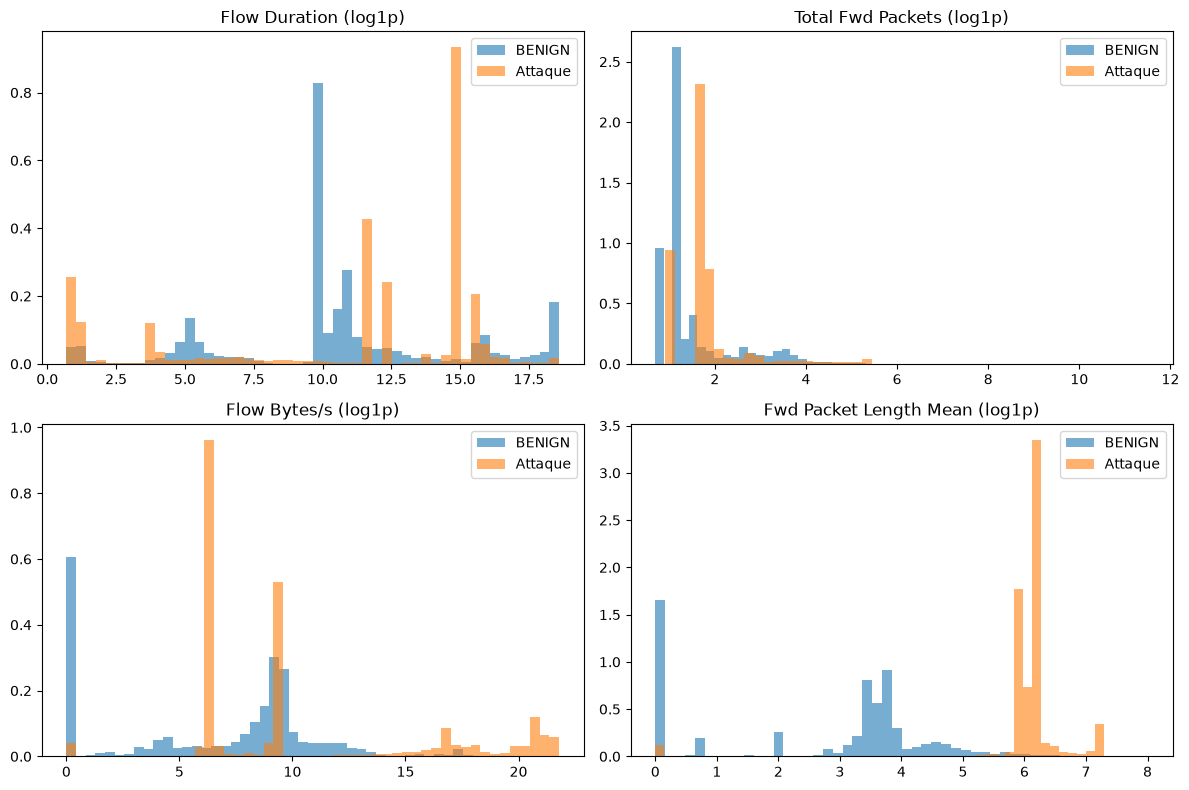

In [10]:
feats = ["Flow Duration", "Total Fwd Packets", "Flow Bytes/s", "Fwd Packet Length Mean"]
is_benign = df["Label"] == "BENIGN"

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, feat in zip(axes.ravel(), feats):
    ax.hist(np.log1p(df.loc[is_benign, feat]), bins=50, alpha=0.6, density=True, label="BENIGN")
    ax.hist(np.log1p(df.loc[~is_benign, feat]), bins=50, alpha=0.6, density=True, label="Attaque")
    ax.set_title(feat + " (log1p)")
    ax.legend()
plt.tight_layout()
plt.show()

Label  BENIGN  DrDoS_DNS  DrDoS_LDAP  DrDoS_MSSQL  DrDoS_NTP  DrDoS_NetBIOS  \
day                                                                           
raw     65524       8543        2936        17670      22833           1706   

Label  DrDoS_SNMP  DrDoS_SSDP  DrDoS_UDP  LDAP  MSSQL  NetBIOS  Portmap   Syn  \
day                                                                             
raw          9236       26324      31547  1875  22809      981      180  3902   

Label    TFTP    UDP  UDP-lag  WebDDoS  
day                                     
raw    163151  37809     2208       10  


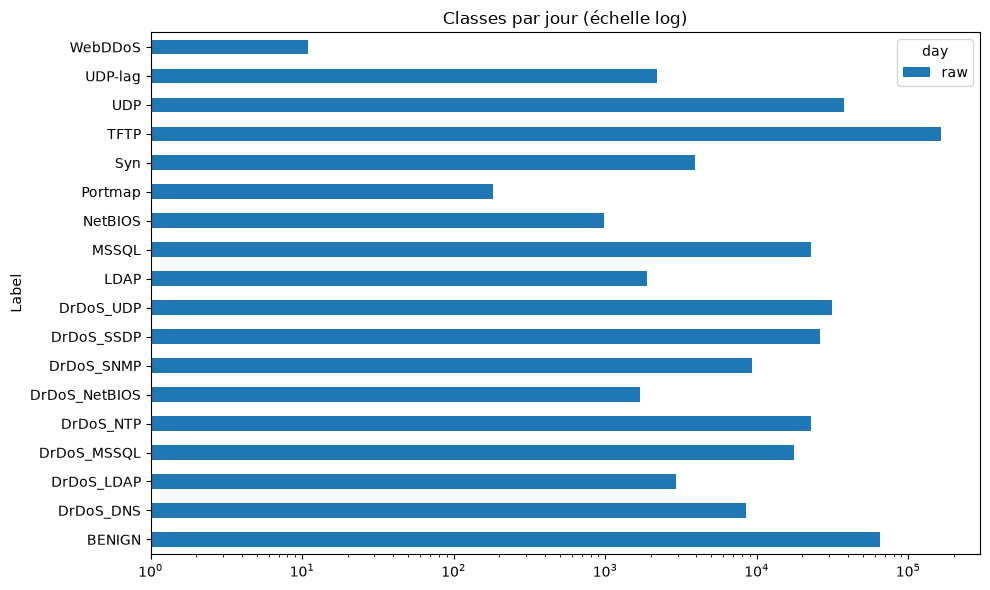

In [11]:
tab = meta.groupby(["day", "Label"]).size().unstack(fill_value=0)
print(tab)

tab.T.plot(kind="barh", figsize=(10, 6), log=True)
plt.title("Classes par jour (échelle log)")
plt.tight_layout()
plt.show()